In [1]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier

from sklearn.metrics import *

In [2]:
data = load_breast_cancer()

X = pd.DataFrame(data.data, columns=data.feature_names)
y = data.target

print("Dataset Shape:", X.shape)
print("Classes:", data.target_names)
print(X.head())

print("\nClass Distribution:")
print(pd.Series(y).map({0: "Malignant", 1: "Benign"}).value_counts())

Dataset Shape: (569, 30)
Classes: ['malignant' 'benign']
   mean radius  mean texture  mean perimeter  mean area  mean smoothness  \
0        17.99         10.38          122.80     1001.0          0.11840   
1        20.57         17.77          132.90     1326.0          0.08474   
2        19.69         21.25          130.00     1203.0          0.10960   
3        11.42         20.38           77.58      386.1          0.14250   
4        20.29         14.34          135.10     1297.0          0.10030   

   mean compactness  mean concavity  mean concave points  mean symmetry  \
0           0.27760          0.3001              0.14710         0.2419   
1           0.07864          0.0869              0.07017         0.1812   
2           0.15990          0.1974              0.12790         0.2069   
3           0.28390          0.2414              0.10520         0.2597   
4           0.13280          0.1980              0.10430         0.1809   

   mean fractal dimension  ...  wor

In [3]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training Samples:", len(X_train))
print("Testing Samples:", len(X_test))

Training Samples: 455
Testing Samples: 114


In [4]:
models = {
    "Logistic Regression": make_pipeline(
        StandardScaler(),
        LogisticRegression(max_iter=5000)
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        random_state=42
    ),

    "Gradient Boosting": GradientBoostingClassifier(
        n_estimators=100,
        random_state=42
    )
}

In [5]:
results = []
trained_models = {}

for name, model in models.items():

    start = time.time()
    model.fit(X_train, y_train)
    train_time = time.time() - start

    y_pred = model.predict(X_test)

    trained_models[name] = model

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, pos_label=0),
        "Recall": recall_score(y_test, y_pred, pos_label=0),
        "F1 Score": f1_score(y_test, y_pred, pos_label=0),
        "Training Time": train_time
    })

In [6]:
results_df = pd.DataFrame(results)

print(results_df.round(4))

                 Model  Accuracy  Precision  Recall  F1 Score  Training Time
0  Logistic Regression    0.9825     0.9762  0.9762    0.9762         0.0320
1        Random Forest    0.9561     0.9512  0.9286    0.9398         0.0834
2    Gradient Boosting    0.9561     0.9744  0.9048    0.9383         0.1883


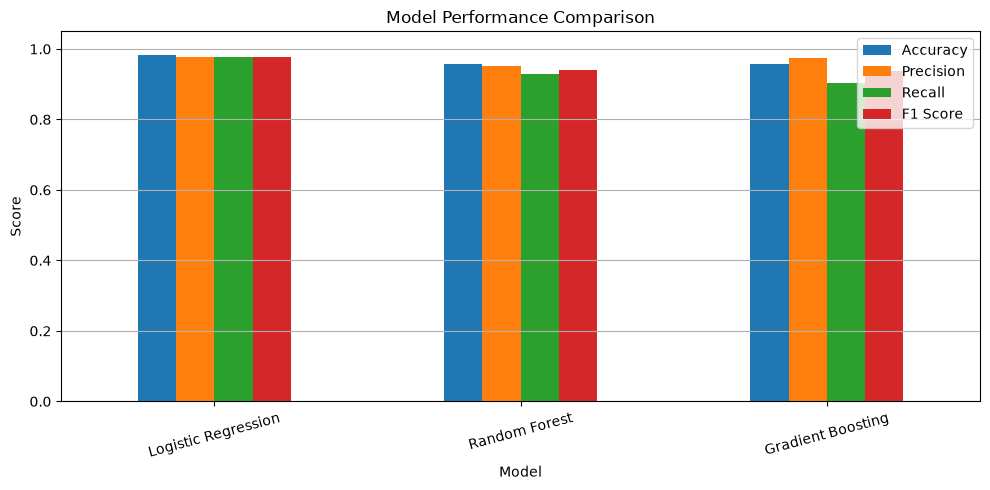

In [7]:
metrics = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1 Score"
]

results_df.set_index("Model")[metrics].plot(
    kind="bar",
    figsize=(10, 5)
)

plt.title("Model Performance Comparison")
plt.ylabel("Score")
plt.ylim(0, 1.05)
plt.xticks(rotation=15)
plt.grid(axis="y")
plt.tight_layout()
plt.show()

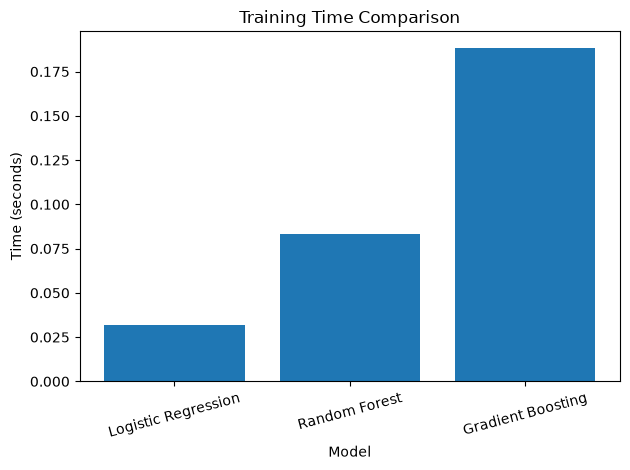

In [8]:
plt.bar(
    results_df["Model"],
    results_df["Training Time"]
)

plt.title("Training Time Comparison")
plt.xlabel("Model")
plt.ylabel("Time (seconds)")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

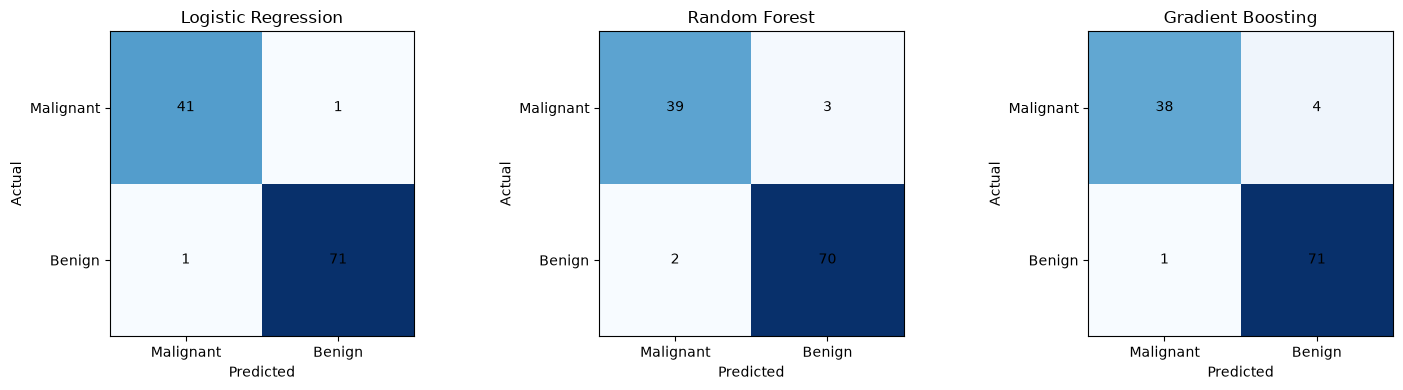

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, (name, model) in zip(axes, trained_models.items()):

    y_pred = model.predict(X_test)
    cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

    ax.imshow(cm, cmap="Blues")

    ax.set_title(name)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")
    ax.set_xticks([0, 1])
    ax.set_yticks([0, 1])
    ax.set_xticklabels(["Malignant", "Benign"])
    ax.set_yticklabels(["Malignant", "Benign"])

    for i in range(2):
        for j in range(2):
            ax.text(j, i, cm[i, j], ha="center", va="center")

plt.tight_layout()
plt.show()

In [10]:
for name, model in trained_models.items():

    print("\n", name)
    y_pred = model.predict(X_test)

    print(classification_report(
        y_test,
        y_pred,
        target_names=data.target_names
    ))


 Logistic Regression
              precision    recall  f1-score   support

   malignant       0.98      0.98      0.98        42
      benign       0.99      0.99      0.99        72

    accuracy                           0.98       114
   macro avg       0.98      0.98      0.98       114
weighted avg       0.98      0.98      0.98       114


 Random Forest
              precision    recall  f1-score   support

   malignant       0.95      0.93      0.94        42
      benign       0.96      0.97      0.97        72

    accuracy                           0.96       114
   macro avg       0.96      0.95      0.95       114
weighted avg       0.96      0.96      0.96       114


 Gradient Boosting
              precision    recall  f1-score   support

   malignant       0.97      0.90      0.94        42
      benign       0.95      0.99      0.97        72

    accuracy                           0.96       114
   macro avg       0.96      0.95      0.95       114
weighted avg    

In [11]:
best = results_df.loc[
    results_df["Recall"].idxmax()
]

print("Best Model:", best["Model"])
print("Accuracy:", best["Accuracy"])
print("Malignant Recall:", best["Recall"])
print("Malignant Precision:", best["Precision"])
print("F1 Score:", best["F1 Score"])

Best Model: Logistic Regression
Accuracy: 0.9824561403508771
Malignant Recall: 0.9761904761904762
Malignant Precision: 0.9761904761904762
F1 Score: 0.9761904761904762


In [12]:
tree_counts = [10, 50, 100, 200, 300]
rf_results = []

for n in tree_counts:

    rf = RandomForestClassifier(
        n_estimators=n,
        random_state=42
    )

    rf.fit(X_train, y_train)
    y_pred = rf.predict(X_test)

    rf_results.append({
        "Trees": n,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Malignant Recall": recall_score(
            y_test, y_pred, pos_label=0
        )
    })

rf_df = pd.DataFrame(rf_results)

print(rf_df.round(4))

   Trees  Accuracy  Malignant Recall
0     10    0.9386            0.9286
1     50    0.9561            0.9286
2    100    0.9561            0.9286
3    200    0.9561            0.9286
4    300    0.9474            0.9286


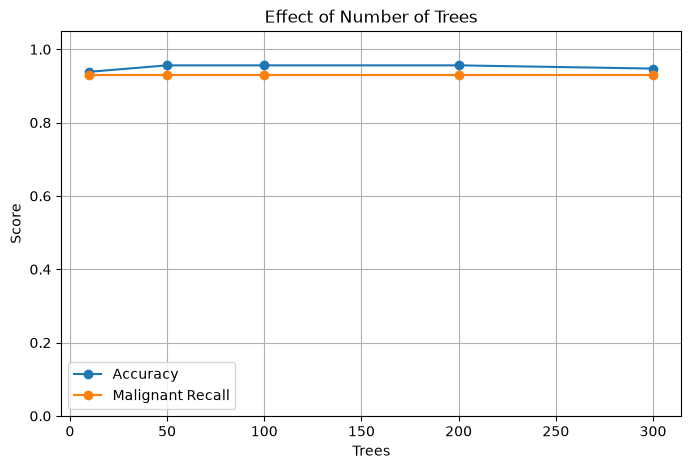

In [13]:
rf_df.set_index("Trees").plot(
    marker="o",
    figsize=(8, 5)
)

plt.title("Effect of Number of Trees")
plt.ylabel("Score")
plt.ylim(0, 1.05)
plt.grid()
plt.show()